
## **TP Epilepsy Seizures sEEG (Dr S.Lagarde - Dr N.Catz)**
M1 Neurosciences 2026-2027

Please find the data https://amubox.univ-amu.fr/s/snJrHZP2zzQ7zDQ


The data contains a segment of sEEG recording with epileptic seizure


The channels of interest are A’1-A’2 and C’1-C’2, as well as GPH’2-GPH’3 in bipolar montage.

The seizure onset time is 17 seconds.

Take a window for the PSD between 17 and 27 seconds to identify the frequency of interest.

Then plot the time-frequency representation between 7 and 37 seconds.

You should observe a seizure discharge at around 7-8 Hz in C’ and GPH’, and at around 80 Hz in A’.

You can also observe the “chimneys” (vertical broadband streaks) of the pre-ictal spikes at around 70-71 seconds.


fs = 512                     # sampling rate (Hz)
notch_freq, notch_q = 50, 30 # mains noise notch filter
band_low, band_high = 1,200  # band-pass range (Hz)

analyse_winonset=64 # Début de l'analyse (en secondes)
analyse_winoffset=100 # Fin de l'analyse (en secondes)

On the next section , open the file 

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import warnings

# --- analysis parameters ---
fs = 512                     # sampling rate (Hz)
notch_freq, notch_q = 50, 30 # mains noise notch filter
band_low, band_high = 1,200  # band-pass range (Hz)

os.getcwd()
if os.getcwd().endswith('scripts_SL'):
    os.chdir('..')
    print(os.getcwd())
 
print(os.getcwd())

d:\DATA\Projets\M1_EEG_Project


In the next cell, we will load the sEEG data from the .npy file and extract the relevant information for further analysis.

In [63]:
data=np.load('./data_SL/sEEG_Seizure_data_SL.npy', allow_pickle=True).item()
data.keys()

eeg_data_segment=data['eeg']
fs=data['fs']
n_channels=data['n_channels']
info=data['info']
print(info)


<Info | 8 non-empty values
 bads: []
 ch_names: TP'1, TP'2, TP'3, TP'4, TP'5, TP'6, TP'7, TP'8, TP'9, TP'10, ...
 chs: 143 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 256.0 Hz
 meas_date: 2026-10-12 14:18:07 UTC
 nchan: 143
 projs: []
 sfreq: 512.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>


in the next cell, we will plot the EEG data 

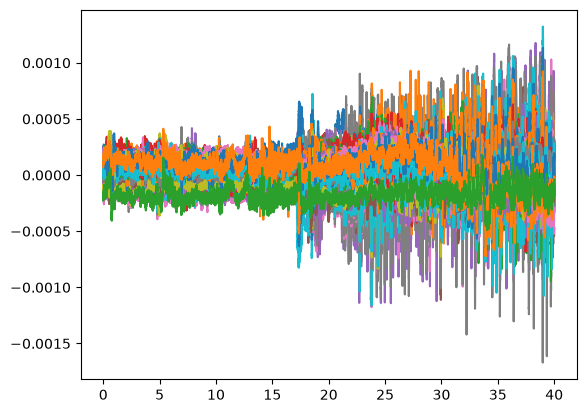

In [64]:
time = np.arange(eeg_data_segment.shape[1]) / fs  # time vector in seconds

plt.plot(time, eeg_data_segment.T)
plt.show()

in the next cell, we will keep only the electrodes A'1-A'2 and C'1-C'2, as well as GPH'2-GPH'3
and plot the corresponding signals

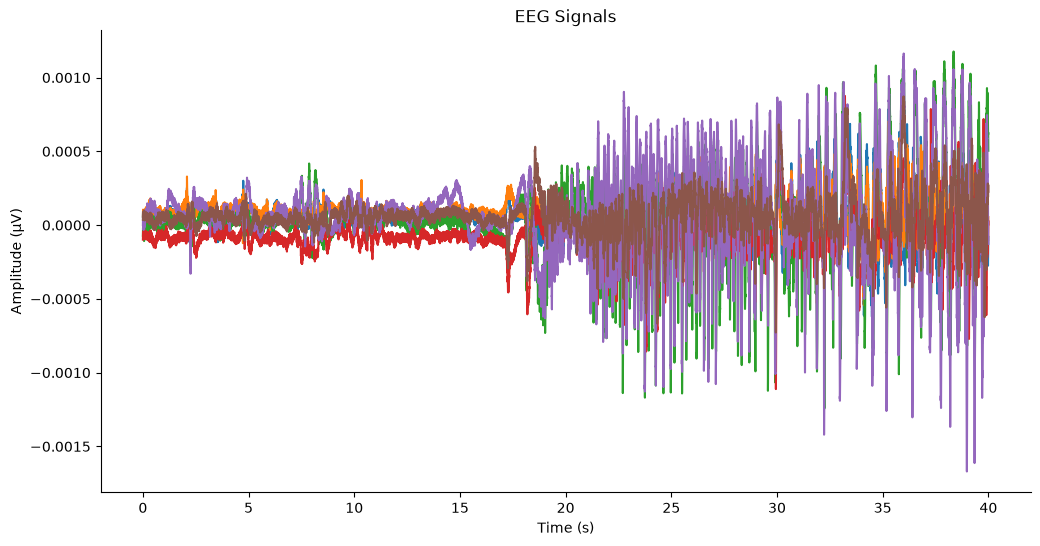

In [65]:
# garde seulement les electrodes A'1-A'2 et C'1-C'2, ainsi que GPH'2-GPH'3
elec_to_keep=["A'1", "A'2", "C'1", "C'2", "GPH'2", "GPH'3"]

elec_to_keep_index=np.where([ch in elec_to_keep for ch in info['ch_names']])[0]
elec_to_keep_index

eeg_data_selected=eeg_data_segment[elec_to_keep_index]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(time, eeg_data_selected.T)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (µV)')
ax.set_title('EEG Signals')    
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()


in the next cell, we will keep only the electrodes A'1-A'2 and C'1-C'2, as well as GPH'2-GPH'3
and plot then with subplots

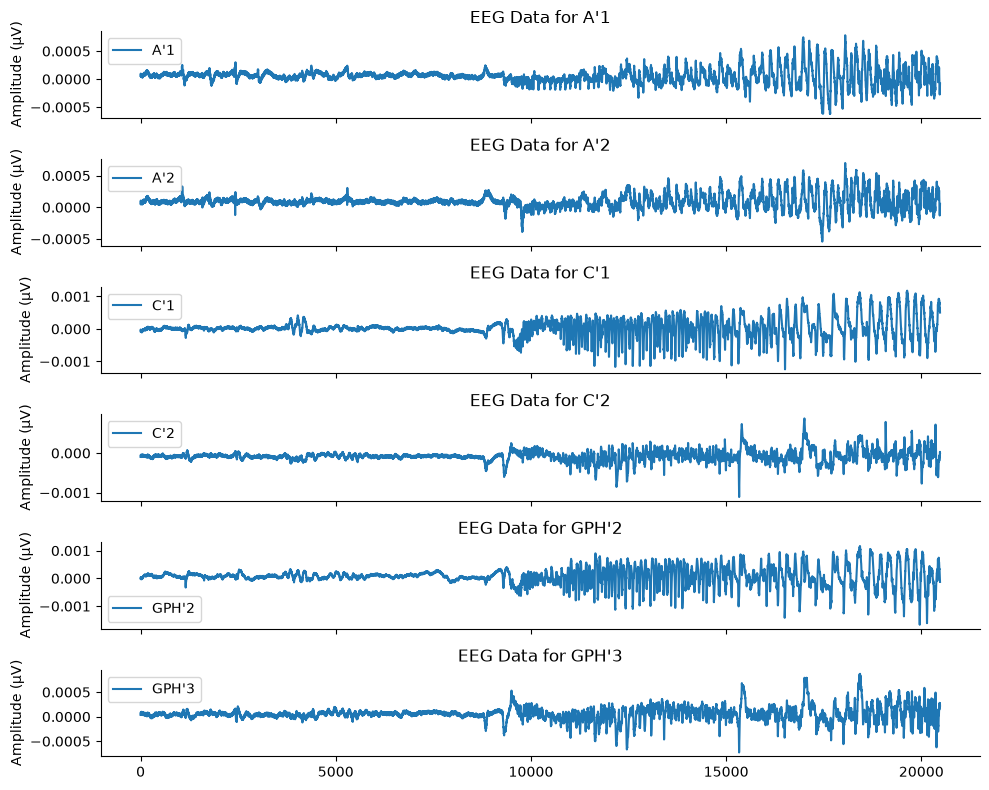

In [66]:
fig, axs = plt.subplots(len(elec_to_keep), 1, figsize=(10, 8), sharex=True)

for i, ch in enumerate(elec_to_keep):
    axs[i].plot(eeg_data_selected[i, :], label=ch)
    axs[i].set_title(f"EEG Data for {ch}")
    axs[i].legend()
    axs[i].set_ylabel("Amplitude (µV)")
    axs[i].spines['top'].set_visible(False)
    axs[i].spines['right'].set_visible(False)
plt.tight_layout()
    


in the next cell, we will filter the data using a notch filter to remove mains noise and a band-pass filter to keep only the frequencies of interest. (cf previous sessions and parameters in the first section)

In [67]:
# filtering eeg_data_selected

from scipy.signal import butter, filtfilt, iirnotch

b, a = iirnotch(notch_freq, notch_q, fs)
eeg_data_notched = filtfilt(b, a, eeg_data_selected)

b,a = butter(4, [band_low/(fs/2), band_high/(fs/2)], btype='band')
eeg_data_filtered = filtfilt(b, a, eeg_data_notched)



plot the filtered data

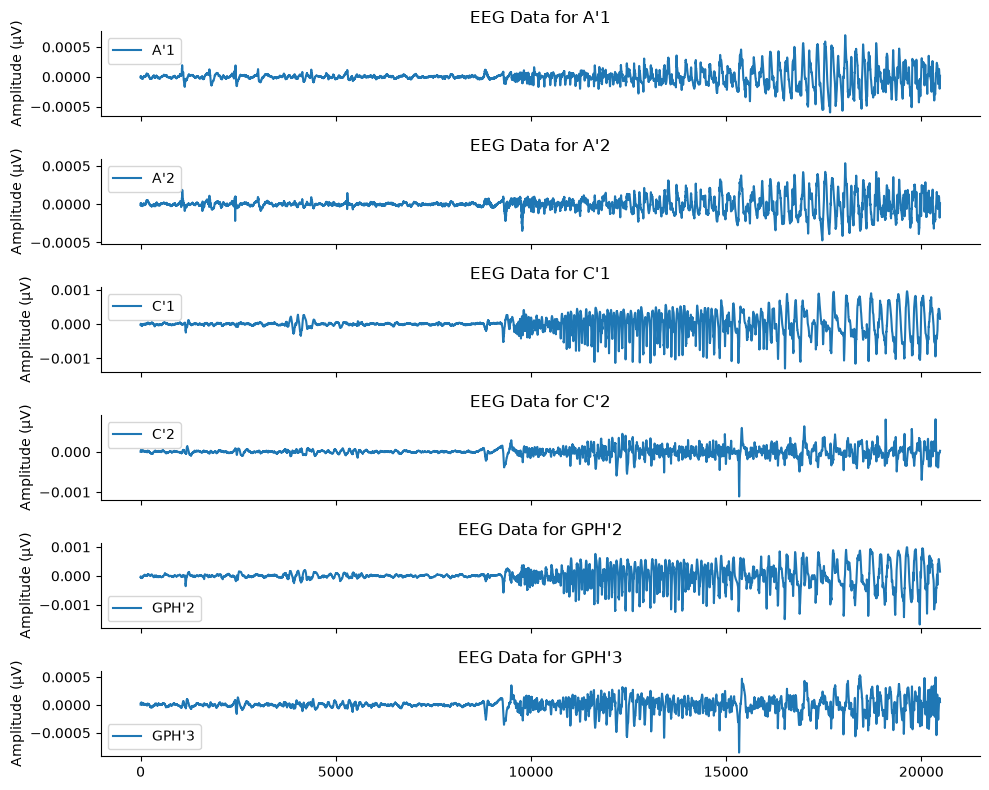

In [68]:
fig, axs = plt.subplots(len(elec_to_keep), 1, figsize=(10, 8), sharex=True)

for i, ch in enumerate(elec_to_keep):
    axs[i].plot(eeg_data_filtered[i, :], label=ch)
    axs[i].set_title(f"EEG Data for {ch}")
    axs[i].legend()
    axs[i].set_ylabel("Amplitude (µV)")
    axs[i].spines['top'].set_visible(False)
    axs[i].spines['right'].set_visible(False)
plt.tight_layout()
    


in the next cell, we want to compute the power spectral density (PSD) of the filtered EEG data using Welch's method. We will use the `scipy.signal.welch` function for this purpose. The PSD will help us understand the frequency content of the EEG signals.


the onset of the sezire is at 17 seconds. We should take a window for the PSD between 17 and 27 seconds to identify the frequency of interest.

we should observe a discharge of the seizure around 7-8 Hz in C' and GPH' and around 80 Hz in A'. We can also observe the "chimneys" of pre-critical peaks around 70-71 seconds.


analyse_winonset=64s # Début de l'analyse (en secondes)
analyse_winoffset=100s # Fin de l'analyse (en secondes)

77 s = seconde 13
87 s = seconde 23

In [75]:
eeg_win[channel,:].shape

(5120,)

(6, 5120)


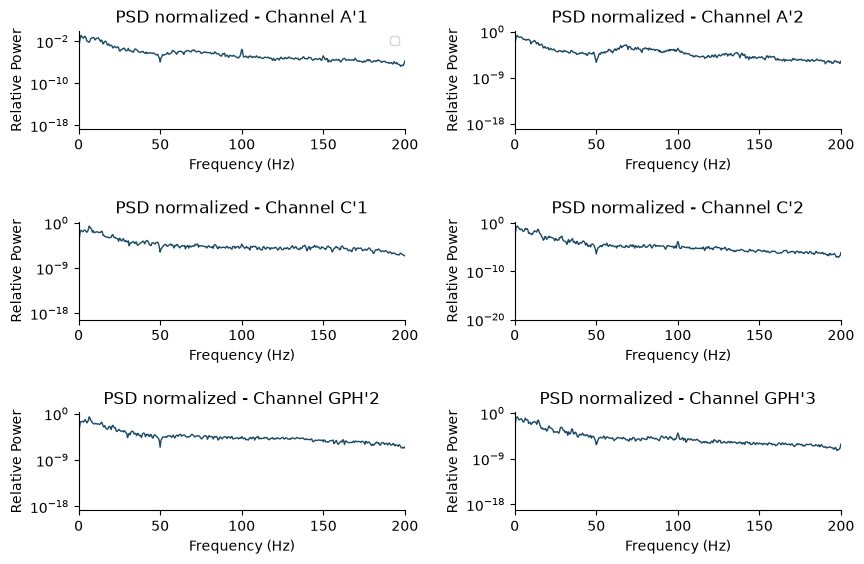

In [85]:

eeg_win=eeg_data_filtered[:,int(13*fs):int(23*fs)]
print(eeg_win.shape)

from scipy.signal import welch

psd_band = (2, 200)    # bande utilisée pour normaliser (correspond au filtre passe-bande)

fig, axs = plt.subplots(3, 2, figsize=(9, 6))
axs=axs.flatten()
alpha_power = []

for i, channel in enumerate(elec_to_keep):

    
    freqs, psd = welch(eeg_win[i,:], fs=fs, nperseg=fs * 2)

    # normalisation : puissance relative (la PSD de chaque canal somme à 1 sur 4-40 Hz)
    norm_mask = (freqs >= psd_band[0]) & (freqs <= psd_band[1])
    psd_norm = psd / psd[norm_mask].sum()

    axs[i].plot(freqs, psd_norm, color='#1B4965', linewidth=1)
    axs[i].set_title(f'PSD normalized - Channel {channel}')
    axs[i].set_yscale('log')
    axs[i].set_ylabel('Relative Power')
    axs[i].spines['top'].set_visible(False)
    axs[i].spines['right'].set_visible(False)
    axs[i].set_xlim([0, psd_band[1]])  # Limiting the x-axis to 0-40 Hz
    axs[i].set_xlabel('Frequency (Hz)')

axs[0].legend(loc='upper right', fontsize=8)

plt.tight_layout(pad=2.0)
plt.show()

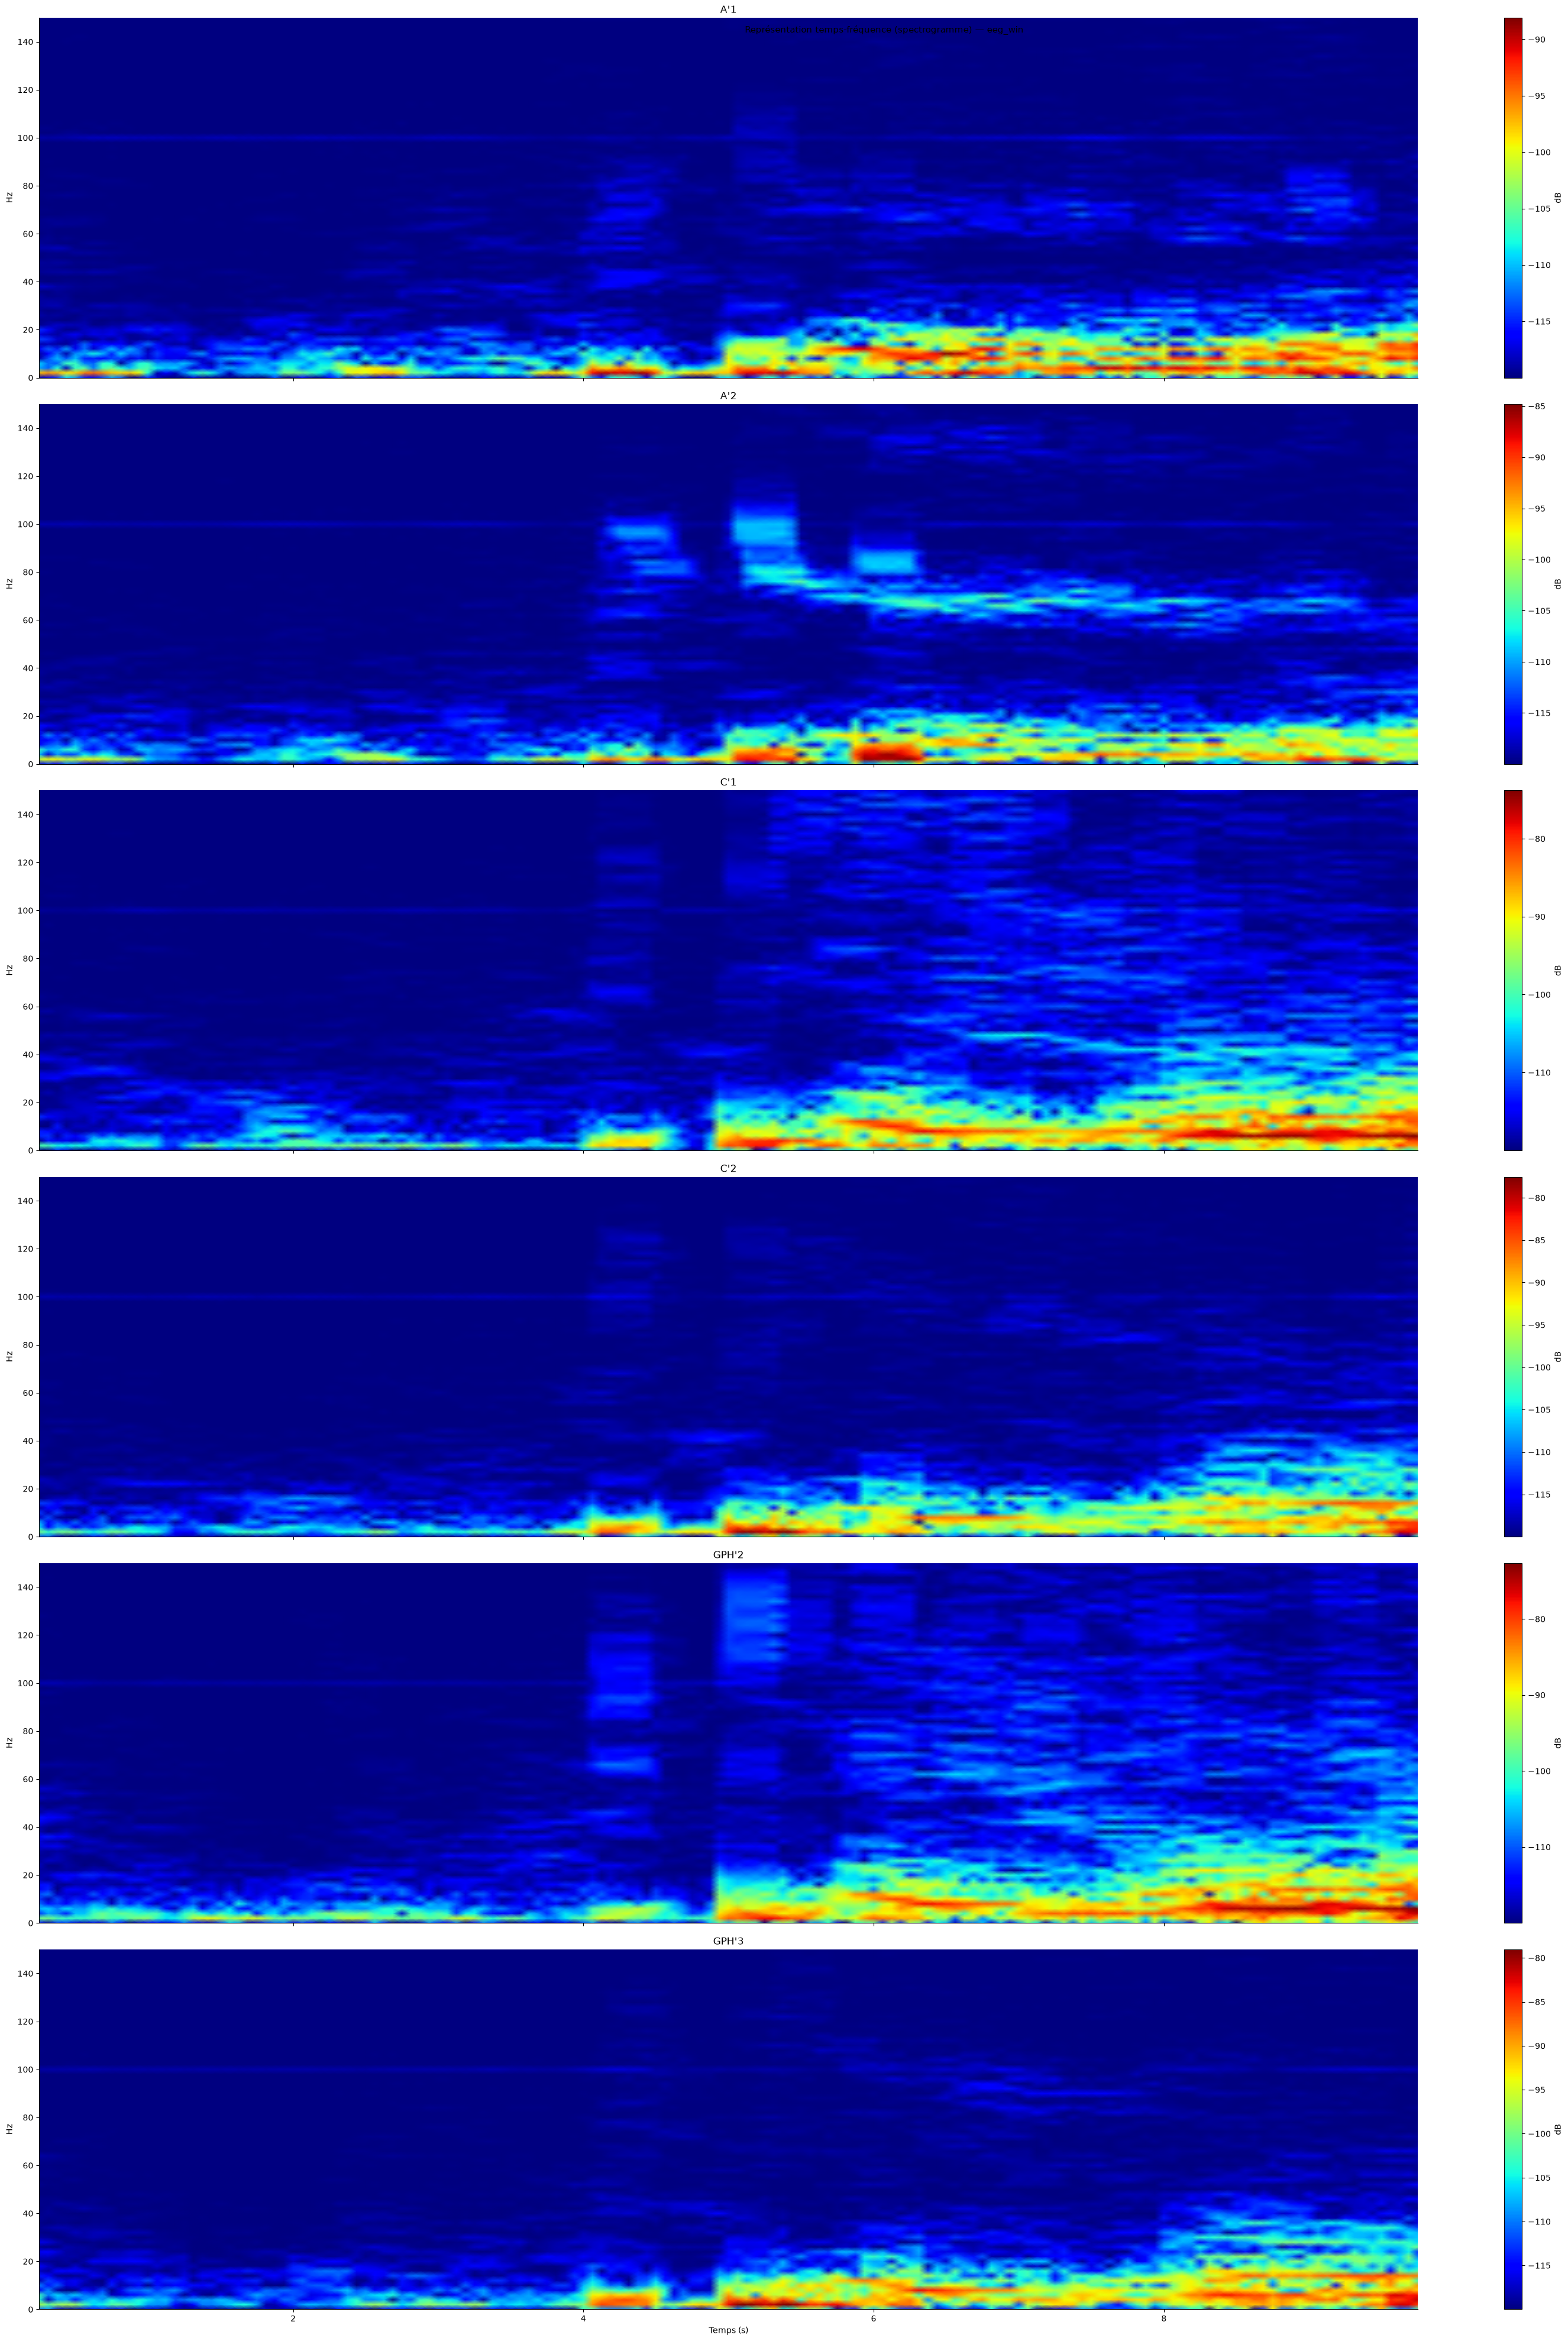

In [70]:
from scipy.signal import spectrogram

fig, axs = plt.subplots(len(elec_to_keep), 1, figsize=(30, 40), sharex=True)

for i, ch in enumerate(elec_to_keep):
    f, t, Sxx = spectrogram(eeg_win[i, :], fs=fs, nperseg=256, noverlap=224, scaling='density')

    # Limiter à 150 Hz et convertir en dB
    freq_mask = f <= 150
    Sxx_db = 10 * np.log10(Sxx[freq_mask] + 1e-12)

    im = axs[i].pcolormesh(t, f[freq_mask], Sxx_db, shading='gouraud', cmap='jet')
    axs[i].set_ylabel('Hz')
    axs[i].set_title(ch, fontsize=12)
    axs[i].spines['top'].set_visible(False)
    axs[i].spines['right'].set_visible(False)
    plt.colorbar(im, ax=axs[i], label='dB')

axs[-1].set_xlabel('Temps (s)')
fig.suptitle('Représentation temps-fréquence (spectrogramme) — eeg_win', fontsize=11)
plt.tight_layout()
plt.show()


In [71]:
from mne.time_frequency import tfr_array_morlet

freqs = np.logspace(np.log10(2), np.log10(150), 80)   # 80 fréquences log-espacées 2–150 Hz
n_cycles = freqs / 2                                    # résolution adaptative (min 1 cycle)
n_cycles = np.clip(n_cycles, 3, 20)

# tfr_array_morlet attend (n_epochs, n_channels, n_times)
epoch_data = eeg_data_filtered[np.newaxis, :, :]                 # (1, 6, n_times)

power = tfr_array_morlet(epoch_data, sfreq=fs, freqs=freqs,
                          n_cycles=n_cycles, output='power')  # (1, 6, n_freqs, n_times)
power = power[0]                                        # (6, n_freqs, n_times)

t = np.arange(eeg_data_filtered.shape[1]) / fs

fig, axs = plt.subplots(len(elec_to_keep), 1, figsize=(30, 40), sharex=True)

for i, ch in enumerate(elec_to_keep):
    power_db = 10 * np.log10(power[i] + 1e-30)

    im = axs[i].pcolormesh(t, freqs, power_db, shading='gouraud', cmap='jet')
    axs[i].set_yscale('log')
    axs[i].set_yticks([2, 5, 10, 20, 50, 100, 150])
    axs[i].set_yticklabels([2, 5, 10, 20, 50, 100, 150], fontsize=7)
    axs[i].set_ylabel('Hz')
    axs[i].set_title(ch, fontsize=9, pad=2)
    axs[i].spines['top'].set_visible(False)
    axs[i].spines['right'].set_visible(False)
    plt.colorbar(im, ax=axs[i], label='dB')

axs[-1].set_xlabel('Temps (s)')
fig.suptitle('Représentation temps-fréquence (ondelettes de Morlet) — eeg_win', fontsize=11)
plt.tight_layout()
plt.show()


KeyboardInterrupt: 